# Extra Trees + SNaive: запуск і порівняння

61 кандидат: Extra Trees з навчанням на 21, 60 та 120 днях; суміші з 5–95% SNaive (крок 5%); окремий SNaive.

Використовуємо 6 початкових вікон для калібрування, 11 вікон для вибору за RMSE на 48 годинах і останнє вікно для окремого аудиту. Три сценарії похибки погоди об’єднуються всередині кожного вікна, а не рахуються як незалежні вікна. Інтервали використовують лише попередні завершені вікна.

Ядро: **Time Series (.venv)**. Нижче збережені виконані результати; **Run All** повторює запуск зі збереженим кешем прогнозів.

In [ ]:
# Run from the repository root so data and results paths resolve.
import os, sys
from pathlib import Path
if Path.cwd().name == 'notebooks':
    os.chdir('..')
sys.path.insert(0, str(Path.cwd()))

In [1]:
from pathlib import Path
import os
import sys
import subprocess
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'session1_extra_snaive.py').exists():
    raise FileNotFoundError('Запустіть ноутбук із папки time_serias')
OUT = ROOT / 'results_extra_snaive'
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': .25})

## Запуск експерименту

`RUN_EXPERIMENT=True` запускає скрипт. За замовчуванням він повторно використовує кеш точкових прогнозів, але перераховує ансамблі й оцінки. Якщо змінюєте дані або налаштування моделі, встановіть `REFIT=True`: це видалить лише три кеші цього експерименту й повторить навчання.

In [2]:
RUN_EXPERIMENT = True
REFIT = False
if RUN_EXPERIMENT:
    if REFIT:
        for days in [21, 60, 120]:
            cache = OUT / f'extra_trees_{days}d_points.npz'
            if cache.exists():
                cache.unlink()
    env = dict(os.environ, OPENBLAS_NUM_THREADS='1', OMP_NUM_THREADS='1')
    subprocess.run([sys.executable, str(ROOT / 'session1_extra_snaive.py')],
                   cwd=ROOT, env=env, check=True)
else:
    print('Читаємо збережені результати.')

                    model       RMSE  RMSE_ratio
 extra_trees_60d_snaive40 271.860088    0.854518
 extra_trees_60d_snaive35 272.184166    0.855536
 extra_trees_60d_snaive45 272.229356    0.855679
 extra_trees_60d_snaive30 273.199122    0.858727
 extra_trees_60d_snaive50 273.289158    0.859010
 extra_trees_60d_snaive25 274.897304    0.864064
 extra_trees_60d_snaive55 275.031512    0.864486
extra_trees_120d_snaive45 275.349466    0.865486
extra_trees_120d_snaive40 275.371620    0.865555
extra_trees_120d_snaive50 276.028962    0.867622
SELECTED extra_trees_60d_snaive40 BEST BLEND extra_trees_60d_snaive40


In [3]:
scores = pd.read_csv(OUT / 'model_comparison.csv')
windows = pd.read_csv(OUT / 'window_comparison.csv', parse_dates=['start', 'end'])
consistency = pd.read_csv(OUT / 'window_consistency.csv')
report = json.loads((OUT / 'run_summary.json').read_text())
winner = report['selected_model']
SCENARIO = 'weather_stress'  # або 'observed_weather'; вибір переможця завжди за weather_stress
print('Обрано:', winner)
print('Кількість кандидатів:', report['candidates'])
selection = scores.query("scenario == @SCENARIO and phase == 'selection' and period == 'full_48h'").copy()
selection = selection.merge(consistency.query('scenario == @SCENARIO')[['model', 'wins', 'windows', 'win_rate']], on='model', validate='one_to_one')
display(selection.sort_values('RMSE')[['model', 'RMSE', 'RMSE_ratio', 'MAPE', 'Winkler', 'coverage', 'wins', 'windows']].head(15).round(3))

Обрано: extra_trees_60d_snaive40
Кількість кандидатів: 61


,model,RMSE,RMSE_ratio,MAPE,Winkler,coverage,wins,windows
0,extra_trees_60d_snaive40,271.860,0.855,383.029,1167.151,0.935,8,11
1,extra_trees_60d_snaive35,272.184,0.856,383.189,1180.053,0.931,8,11
2,extra_trees_60d_snaive45,272.229,0.856,382.991,1164.688,0.939,8,11
3,extra_trees_60d_snaive30,273.199,0.859,383.431,1196.102,0.927,8,11
4,extra_trees_60d_snaive50,273.289,0.859,383.080,1158.899,0.941,8,11
5,extra_trees_60d_snaive25,274.897,0.864,383.745,1220.595,0.929,8,11
6,extra_trees_60d_snaive55,275.032,0.864,383.250,1152.460,0.943,8,11
7,extra_trees_120d_snaive45,275.349,0.865,469.985,1154.085,0.936,8,11
8,extra_trees_120d_snaive40,275.372,0.866,477.951,1166.487,0.934,8,11
9,extra_trees_120d_snaive50,276.029,0.868,462.099,1146.241,0.943,8,11


## Як вага SNaive впливає на точність

Крайні точки 0% і 100% — окремі Extra Trees та SNaive. Ваги вибираються за всіма 48 годинами; графік другого дня показує іншу ціль оцінювання.

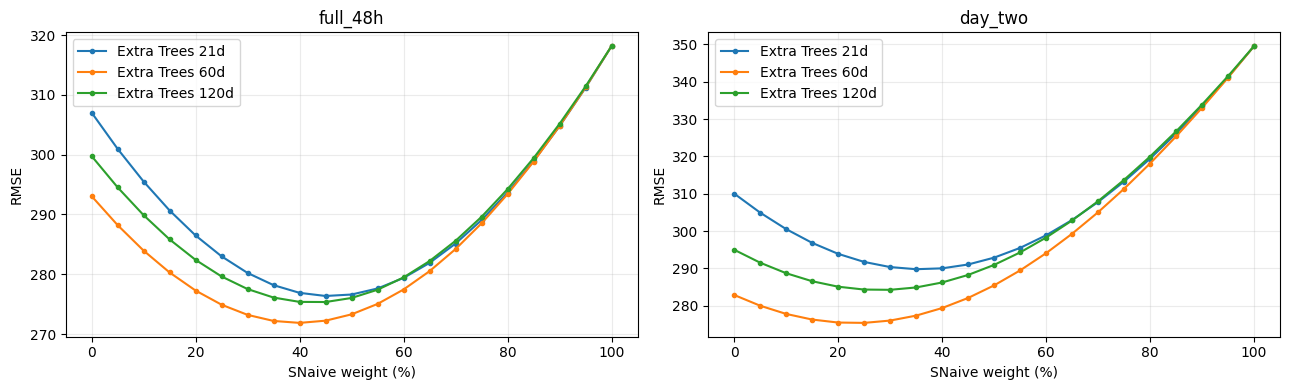

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, period in zip(axes, ['full_48h', 'day_two']):
    part = scores.query("scenario == @SCENARIO and phase == 'selection' and period == @period").set_index('model')
    for days in [21, 60, 120]:
        names = [f'extra_trees_{days}d'] + [f'extra_trees_{days}d_snaive{n}' for n in range(5, 100, 5)] + ['seasonal_naive']
        ax.plot(range(0, 101, 5), part.loc[names, 'RMSE'], marker='.', label=f'Extra Trees {days}d')
    ax.set(title=period, xlabel='SNaive weight (%)', ylabel='RMSE')
    ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'weight_comparison.png', dpi=150)
plt.show()

## Переможець, окремі моделі та останнє контрольне вікно

Аудит не використовується для вибору ваг. Він уже переглядався у попередніх експериментах і не є недоторканим тестом.

phase                    last_window_audit          selection         
period                             day_two full_48h   day_two full_48h
model                                                                 
extra_trees_120d                    216.82   219.16    295.02   299.76
extra_trees_21d                     259.79   238.72    310.05   307.03
extra_trees_60d                     241.17   226.41    282.92   293.05
extra_trees_60d_snaive40            131.19   142.62    279.41   271.86
seasonal_naive                      147.68   120.40    349.50   318.14

,model,wins,windows,win_rate,worst_RMSE_ratio
81,extra_trees_60d_snaive40,8,11,0.727,1.483
115,extra_trees_120d,7,11,0.636,2.093
117,extra_trees_60d,6,11,0.545,1.919
120,extra_trees_21d,4,11,0.364,2.158
121,seasonal_naive,0,11,0.000,1.000


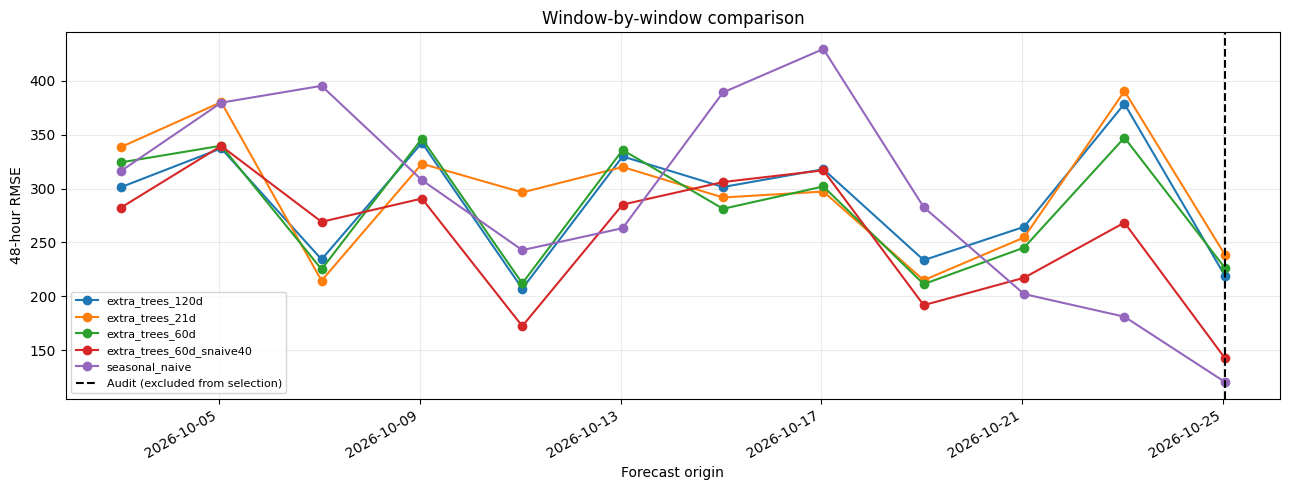

In [5]:
focus = list(dict.fromkeys([winner, 'extra_trees_21d', 'extra_trees_60d', 'extra_trees_120d', 'seasonal_naive']))
display(scores.query('scenario == @SCENARIO and model in @focus').pivot_table(
    index='model', columns=['phase', 'period'], values='RMSE').round(2))
display(consistency.query('scenario == @SCENARIO and model in @focus')[['model', 'wins', 'windows', 'win_rate', 'worst_RMSE_ratio']].round(3))
plot = windows.query('scenario == @SCENARIO and model in @focus').pivot(index='start', columns='model', values='RMSE')
ax = plot.plot(marker='o', figsize=(13, 5))
audit_start = windows.query("phase == 'last_window_audit'")['start'].min()
ax.axvline(audit_start, color='black', linestyle='--', label='Audit (excluded from selection)')
ax.set(ylabel='48-hour RMSE', xlabel='Forecast origin', title='Window-by-window comparison')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / 'window_comparison.png', dpi=150)
plt.show()

## Порівняння з попереднім найкращим ансамблем

Точкові RMSE порівнюються на тих самих 11 вікнах і сценаріях. Для великого пошуку було перевірено 66 845 кандидатів, тому його мінімальний RMSE сильніше залежить від підбору на валідації. Метрики інтервалів тут не порівнюємо.

In [6]:
prior_path = ROOT / 'results_snaive_search/all_combinations.csv'
if prior_path.exists():
    prior = pd.read_csv(prior_path).sort_values('RMSE').iloc[0]
    rows = []
    for name in [winner, 'extra_trees_60d', 'seasonal_naive']:
        subset = scores.query("scenario == 'weather_stress' and phase == 'selection' and model == @name").set_index('period')
        rows.append({'model': name, 'RMSE_48h': subset.loc['full_48h', 'RMSE'], 'RMSE_day2': subset.loc['day_two', 'RMSE']})
    rows.append({'model': 'Prior large-search winner', 'RMSE_48h': prior.RMSE, 'RMSE_day2': prior.day_two_RMSE})
    display(pd.DataFrame(rows).round(2))
    print('Ваги попереднього переможця:', prior.weights)
else:
    print('Попередній великий пошук відсутній.')

,model,RMSE_48h,RMSE_day2
0,extra_trees_60d_snaive40,271.86,279.41
1,extra_trees_60d,293.05,282.92
2,seasonal_naive,318.14,349.50
3,Prior large-search winner,232.55,249.17


Ваги попереднього переможця: {"day1": {"seasonal_naive": 0.1, "hour_weather_ridge_60d": 0.2, "timestral_28m_weather_504h": 0.7}, "day2": {"seasonal_naive": 0.1, "hour_weather_ridge_60d": 0.2, "timestral_28m_weather_504h": 0.7}}


## Прогноз наступних 48 годин

Це прогноз найкращого кандидата **в межах Extra Trees + SNaive**. Він не замінює прогноз попереднього загального переможця. Емпіричні інтервали не гарантують 95% покриття на майбутніх даних.

,ds,forecast,lower_95,upper_95
0,2026-10-27 01:00:00,194.60,0.0,739.10
1,2026-10-27 02:00:00,181.98,0.0,726.48
2,2026-10-27 03:00:00,191.07,0.0,735.57
3,2026-10-27 04:00:00,203.54,0.0,748.04
4,2026-10-27 05:00:00,213.34,0.0,757.84
5,2026-10-27 06:00:00,212.04,0.0,756.54
6,2026-10-27 07:00:00,439.98,0.0,984.48
7,2026-10-27 08:00:00,475.81,0.0,1020.31


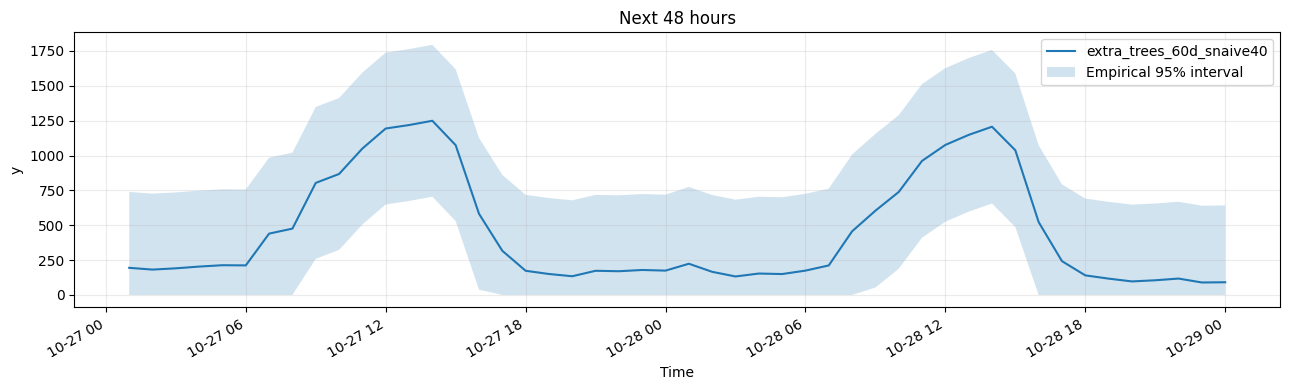

CSV: /Users/alona/Documents/KSE/time_serias/results_extra_snaive/selected_model_forecast.csv


In [7]:
forecast = pd.read_csv(OUT / 'selected_model_forecast.csv', parse_dates=['ds'])
assert len(forecast) == 48 and forecast.ds.is_unique
assert np.isfinite(forecast.iloc[:, 1:]).all().all()
assert (forecast.lower_95 <= forecast.forecast).all() and (forecast.forecast <= forecast.upper_95).all()
display(forecast.head(8).round(2))
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(forecast.ds, forecast.forecast, label=winner)
ax.fill_between(forecast.ds, forecast.lower_95.to_numpy(), forecast.upper_95.to_numpy(), alpha=.2, label='Empirical 95% interval')
ax.set(title='Next 48 hours', ylabel='y', xlabel='Time')
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(OUT / 'selected_forecast.png', dpi=150)
plt.show()
print('CSV:', OUT / 'selected_model_forecast.csv')

## Обмеження

- Валідаційні вікна повторно використовувалися для багатьох експериментів; оцінка обраного переможця може бути оптимістичною.
- Похибки прогнозу погоди змодельовані умовно, а не оцінені за архівом реальних прогнозів.
- MAPE чутливий до малих фактичних значень.
- Extra Trees використовує лаги не менше 48 годин, доступні для всього горизонту; навчання не бачить майбутніх цілей.

Codex допоміг реалізувати й виконати експеримент та підготувати цей ноутбук.